# Handwritten Digit Classifier (MNIST) with Deep Learning

In this project we build a **deep neural network** with TensorFlow/Keras that recognises handwritten digits (0–9) from the **MNIST** dataset (60,000 training and 10,000 test images, each 28×28 pixels, grayscale).

**What this notebook covers**
1. Loading the dataset
2. Preprocessing (normalisation, flattening, one-hot encoding)
3. Model architecture: 3 hidden layers + **Batch Normalization** + **Dropout**
4. Training with a validation split
5. Visualising training vs. validation accuracy and loss
6. Evaluating on the test set (accuracy, confusion matrix, misclassified examples)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Dataset Loading

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("x_train shape:", x_train.shape, "| y_train shape:", y_train.shape)
print("x_test shape: ", x_test.shape,  "| y_test shape: ", y_test.shape)
print("Pixel value range:", x_train.min(), "to", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28) | y_train shape: (60000,)
x_test shape:  (10000, 28, 28) | y_test shape:  (10000,)
Pixel value range: 0 to 255


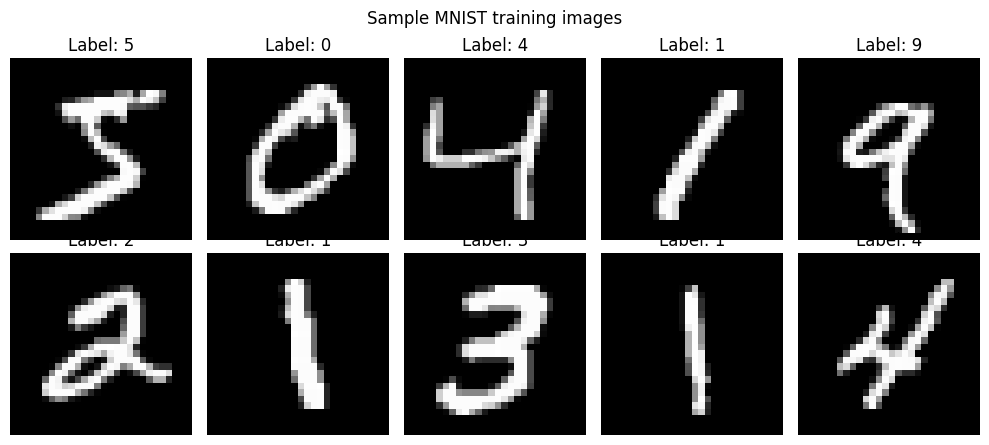

In [ ]:
#few sample images
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("Sample MNIST training images")
plt.tight_layout()
plt.show()

## 2. Preprocessing
- **Normalise** pixel values from [0, 255] to [0, 1] so the network trains faster and more stably.
- **Flatten** each 28×28 image into a 784-length vector (we use a dense network).
- **One-hot encode** the labels so we can use `categorical_crossentropy`.

In [ ]:
#normalise to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

#flatten 28x28 -> 784
x_train = x_train.reshape(-1, 28 * 28)
x_test  = x_test.reshape(-1, 28 * 28)

#one-hot encode labels (keep the integer labels for the report later)
y_train_cat = to_categorical(y_train, num_classes=10)
y_test_cat  = to_categorical(y_test,  num_classes=10)

print("x_train:", x_train.shape, "| range:", x_train.min(), "-", x_train.max())
print("y_train_cat:", y_train_cat.shape)

x_train: (60000, 784) | range: 0.0 - 1.0
y_train_cat: (60000, 10)


## 3. Model Architecture
The network has **3 hidden layers** (256 → 128 → 64 units). Each hidden block follows the pattern:

`Dense → Batch Normalization → ReLU → Dropout`

- **Batch Normalization** stabilises and speeds up training by normalising layer activations.
- **Dropout** randomly switches off a fraction of neurons during training to reduce overfitting.
- The output layer uses **softmax** to produce probabilities for the 10 digit classes.

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(784,)),

    # Hidden layer 1
    layers.Dense(256),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    # Hidden layer 2
    layers.Dense(128),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.3),

    # Hidden layer 3
    layers.Dense(64),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.2),

    # Output layer
    layers.Dense(10, activation="softmax"),
], name="mnist_dense_bn_dropout")

model.summary()

Model: "mnist_dense_bn_dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,554 (955.29 KB)

 Trainable params: 243,658 (951.79 KB)

 Non-trainable params: 896 (3.50 KB)

## 4. Training
- **Loss:** `categorical_crossentropy` (multi-class classification with one-hot labels)
- **Optimizer:** Adam
- **Validation split:** 10% of the training data is held out to monitor generalisation
- **Epochs:** 15, batch size 128

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    x_train, y_train_cat,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    verbose=1,
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.8574 - loss: 0.4948 - val_accuracy: 0.9625 - val_loss: 0.1246
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9361 - loss: 0.2172 - val_accuracy: 0.9738 - val_loss: 0.0844
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9515 - loss: 0.1654 - val_accuracy: 0.9758 - val_loss: 0.0753
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9584 - loss: 0.1370 - val_accuracy: 0.9770 - val_loss: 0.0726
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9645 - loss: 0.1186 - val_accuracy: 0.9800 - val_loss: 0.0677
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9679 - loss: 0.1065 - val_accuracy: 0.9830 - val_loss: 0.0624
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9706 - loss: 0.0947 - val_accuracy: 0.9815 - val_loss: 0.0637
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9728 - loss: 0.0878 - val_accuracy

## 5. Visualization
Training vs. validation **accuracy** and **loss** over epochs. A small gap between the two curves indicates the model is generalising well.

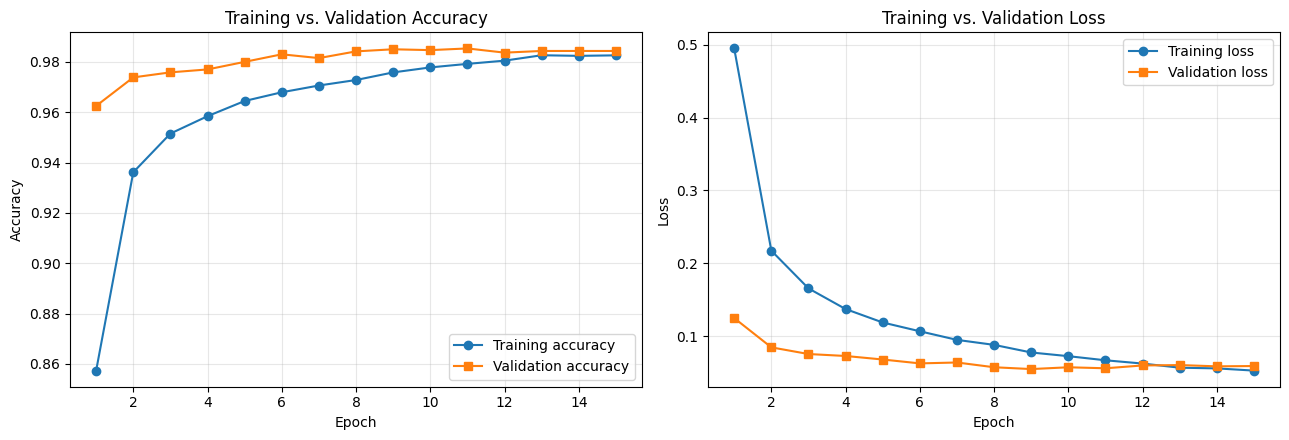

In [ ]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Accuracy
axes[0].plot(epochs_range, history.history["accuracy"],     marker="o", label="Training accuracy")
axes[0].plot(epochs_range, history.history["val_accuracy"], marker="s", label="Validation accuracy")
axes[0].set_title("Training vs. Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Loss
axes[1].plot(epochs_range, history.history["loss"],     marker="o", label="Training loss")
axes[1].plot(epochs_range, history.history["val_loss"], marker="s", label="Validation loss")
axes[1].set_title("Training vs. Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Evaluation

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test_cat, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}  ({test_acc * 100:.2f}%)")

Test loss:     0.0661
Test accuracy: 0.9828  (98.28%)


In [ ]:
# Predictions on the test set
y_pred_probs = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.9779    0.9939    0.9858       980
           1     0.9895    0.9921    0.9908      1135
           2     0.9797    0.9797    0.9797      1032
           3     0.9881    0.9842    0.9861      1010
           4     0.9766    0.9766    0.9766       982
           5     0.9909    0.9798    0.9853       892
           6     0.9895    0.9812    0.9853       958
           7     0.9721    0.9844    0.9783      1028
           8     0.9845    0.9774    0.9809       974
           9     0.9801    0.9772    0.9787      1009

    accuracy                         0.9828     10000
   macro avg     0.9829    0.9826    0.9827     10000
weighted avg     0.9828    0.9828    0.9828     10000



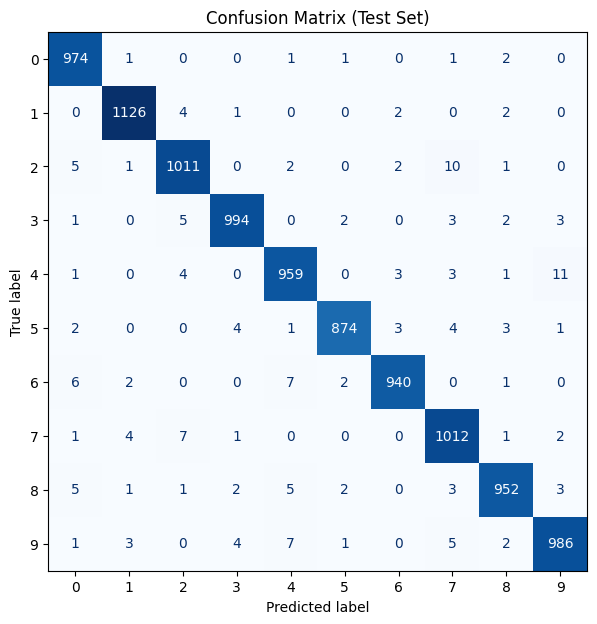

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(7, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix (Test Set)")
plt.show()

Misclassified images: 172 out of 10000


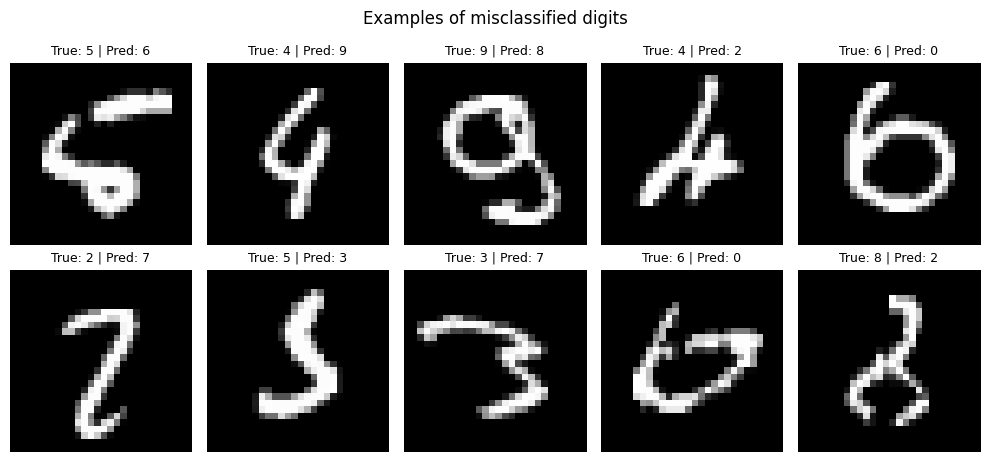

In [ ]:
# Show some misclassified test images
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Misclassified images: {len(wrong_idx)} out of {len(y_test)}")

fig, axes = plt.subplots(2, 5, figsize=(10, 4.8))
for ax, idx in zip(axes.flat, wrong_idx[:10]):
    ax.imshow(x_test[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"True: {y_test[idx]} | Pred: {y_pred[idx]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Examples of misclassified digits")
plt.tight_layout()
plt.show()

#Conclusion
- A dense network with **3 hidden layers, Batch Normalization and Dropout** reaches roughly **98%+ test accuracy** on MNIST (exact value varies slightly per run).
- **Batch Normalization** helped training converge quickly and smoothly.
- **Dropout** kept the gap between training and validation accuracy small, which shows reduced overfitting.
- The confusion matrix shows the few remaining errors are mostly between visually similar digits (e.g. 4 ↔ 9, 3 ↔ 5, 7 ↔ 2), and many misclassified images are genuinely ambiguous.

**Possible improvements:** use a Convolutional Neural Network (CNN), add data augmentation, apply early stopping / learning-rate scheduling, or tune the dropout rate and layer sizes.